# EcoHome Energy Advisor - Agent Run & Evaluation

In this notebook, you'll run the Energy Advisor agent with various real-world scenarios and see how it helps customers optimize their energy usage.

## Learning Objectives
- Create the agent's instructions
- Run the Energy Advisor with different types of questions
- Evaluate response quality and accuracy
- Measure tool usage effectiveness
- Identify areas for improvement
- Implement evaluation metrics

## Evaluation Criteria
- **Accuracy**: Correct information and calculations
- **Relevance**: Responses address the user's question
- **Completeness**: Comprehensive answers with actionable advice
- **Tool Usage**: Appropriate use of available tools
- **Reasoning**: Clear explanation of recommendations


## 1. Import and Initialize

In [1]:
from datetime import datetime
import json
import os
import re
import time

import pandas as pd
from agent import Agent

In [2]:
## The agent's instructions
# Structure: who the advisor is, the steps it follows, what it can do (its tools), how to write
# recommendations, and example questions. Rules that matter for correctness are stated as rules
# ("never invent numbers") rather than as style.

ECOHOME_SYSTEM_PROMPT = """
You are the EcoHome Energy Advisor, an assistant for EcoHome customers who have rooftop solar panels,
an electric vehicle (EV), a smart thermostat (HVAC) and household appliances. Your job is to help each
customer lower their electricity cost and environmental impact with specific, data-backed recommendations.

## How you work, step by step
1. Read the question and the context. The context gives the current date and time, tomorrow's date, the
   next seven dates with their weekday names, and the customer's location. Take the exact dates the question
   refers to ("tomorrow", "Wednesday", "this week") from that list; never work out a weekday yourself.
2. Gather the data the question needs, using the tools below. Call each tool with exact arguments:
   dates as YYYY-MM-DD, the customer's location for weather. For tomorrow, request the forecast with
   days=2 and the prices for tomorrow's date. For a day later this week, request enough forecast days to reach it.
3. Analyse: compare hourly prices with forecast solar generation, and the customer's history where relevant.
4. Recommend: give the specific hours, settings or actions, with the numbers that justify them.
5. Quantify: when the customer asks what they would save, use calculate_energy_savings and quote its
   summary sentence, which states each figure with its period (savings_usd is per period,
   annual_savings_usd is per year). For a time shift, pass date, current_hours and optimized_hours so the
   tool looks up the time-of-use rates itself. The kWh to move is the use in the hours being moved (sum
   the device's hour_of_day_profile over those hours from query_energy_usage), not the whole day's use.
   Never use average_cost_per_kwh from the usage history as today's rate: those past costs were billed on
   an older flat tariff, not the time-of-use prices.
6. Support with best practice: search the knowledge base for relevant tips and cite the source document.

## Your capabilities (tools)
- get_weather_forecast: hourly forecast with solar irradiance and estimated solar generation for this home.
- get_electricity_prices: hourly time-of-use prices for a date, with cheapest and most expensive hours.
- query_energy_usage: the customer's past consumption by day, device type (EV, HVAC, appliance) and hour of day.
- query_solar_generation: the customer's past solar generation by day, hour and weather.
- get_recent_energy_summary: use and generation over the last few hours.
- search_energy_tips: energy-saving articles (EV charging, HVAC, appliances, solar, storage, seasonal, automation).
- calculate_energy_savings: savings from using less energy and/or shifting the same energy to cheaper hours.
  To value a time shift, keep the kWh the same and give date, current_hours and optimized_hours.

## Rules for recommendations
- Every number you state (price, kWh, cost, saving, temperature) must come from a tool result or from a
  calculation you show from tool results. Never invent figures. If a figure is an estimate, say so.
- Be specific: name the hours (e.g. "23:00-05:00"), the date and the setting (e.g. "78°F / 25.5°C").
- For a deadline ("before 7am tomorrow"), the window starts now: tonight's off-peak hours count. When you
  plan charging, state the charger power you assume (e.g. 7.2 kW for a home charger) and never schedule
  more kWh in an hour than that power allows.
- Explain the trade-off between price and solar availability when both matter, and say which you prioritised.
- Mention the data's limits when they matter: forecasts and prices for future dates are estimates; history
  covers only the dates in the database.
- If a tool returns an error, correct the arguments and try once more; if it still fails, say what you could not check.
- Keep the answer short and structured: Recommendation, Why (the data), Estimated savings (when relevant),
  Tips (with sources).
- Stay on energy topics; if the question is outside them, say so briefly.

## Example questions you handle
- "When should I charge my electric car tomorrow to minimize cost and maximize solar power?"
- "What temperature should I set my thermostat on Wednesday afternoon if electricity prices spike?"
- "Suggest three ways I can reduce energy use based on my usage history."
- "How much can I save by running my dishwasher during off-peak hours?"
- "What's the best time to run my pool pump this week based on the weather forecast?"
""".strip()

print(f"System prompt: {len(ECOHOME_SYSTEM_PROMPT.split())} words")

System prompt: 692 words


In [3]:
ecohome_agent = Agent(
    instructions=ECOHOME_SYSTEM_PROMPT,
)

In [4]:
response = ecohome_agent.invoke(
    question="When should I charge my electric car tomorrow to minimize cost and maximize solar power?",
    context="Location: San Francisco, CA"
)

In [5]:
print(response["messages"][-1].content)

### Recommendation
Charge your electric vehicle (EV) tomorrow, November 20, 2026, between **10:00 AM and 2:00 PM**. This time frame maximizes solar power generation while minimizing electricity costs.

### Why
1. **Solar Generation**: The estimated solar generation for tomorrow is **35.64 kWh**, with the best solar hours being from **10:00 AM to 2:00 PM**. During this period, the solar irradiance is highest, allowing your solar panels to produce the most energy.
2. **Electricity Prices**: The time-of-use electricity prices for tomorrow are as follows:
   - **Off-Peak**: 12:00 AM - 5:00 AM, 10:00 PM - 11:59 PM (rates around $0.111 - $0.113)
   - **Mid-Peak**: 6:00 AM - 4:00 PM (rates around $0.159 - $0.162)
   - **Peak**: 4:00 PM - 8:00 PM (rates around $0.255 - $0.260)

   Charging during the **mid-peak hours** (10:00 AM - 2:00 PM) allows you to take advantage of solar generation while keeping costs lower than peak hours.

### Estimated Savings
By charging your EV during the recommende

In [6]:
print("TOOLS:")
for msg in response["messages"]:
    obj = msg.model_dump()
    if obj.get("tool_call_id"):
        print("-", msg.name)

TOOLS:
- get_weather_forecast
- get_electricity_prices


## 2. Define Test Cases

In [7]:
# Test cases: at least 10, covering every scenario family the project names.
# Each case lists:
#   expected_tools   - tools the answer cannot be correct without (scored for completeness)
#   acceptable_tools - extra tools that are reasonable to call (not penalised as inappropriate)
#   expected_response - what a good answer contains (used by the response judge)
SCENARIOS = ["EV charging optimization", "Thermostat settings", "Appliance scheduling",
             "Solar power maximization", "Cost savings calculations", "Usage history analysis"]

In [8]:
test_cases = [
    {
        "id": "ev_charging_1",
        "category": "EV charging optimization",
        "question": "When should I charge my electric car tomorrow to minimize cost and maximize solar power?",
        "expected_tools": ["get_weather_forecast", "get_electricity_prices"],
        "acceptable_tools": ["search_energy_tips", "calculate_energy_savings", "query_energy_usage", "query_solar_generation"],
        "expected_response": "The response should contain time recommendation, cost analysis and solar consideration",
    },
    {
        "id": "ev_charging_overnight",
        "category": "EV charging optimization",
        "question": "I need to add 40 kWh to my EV before 7am tomorrow. Which hours should I charge in, and roughly what will it cost?",
        "expected_tools": ["get_electricity_prices"],
        "acceptable_tools": ["get_weather_forecast", "calculate_energy_savings", "search_energy_tips"],
        "expected_response": "Names specific off-peak hours before 07:00, uses the hourly rates for those hours, and estimates the cost of 40 kWh (about 40 x the off-peak rate).",
    },
    {
        "id": "thermostat_price_spike",
        "category": "Thermostat settings",
        "question": "What temperature should I set my thermostat on Wednesday afternoon if electricity prices spike?",
        "expected_tools": ["get_electricity_prices", "get_weather_forecast"],
        "acceptable_tools": ["search_energy_tips", "query_energy_usage", "calculate_energy_savings"],
        "expected_response": "Works out the date of the coming Wednesday, checks that day's afternoon prices and forecast temperature, and recommends a specific setpoint (raised when cooling, lowered when heating) with pre-cooling or pre-heating before the peak.",
    },
    {
        "id": "thermostat_best_practice",
        "category": "Thermostat settings",
        "question": "What thermostat settings save the most energy without making the house uncomfortable?",
        "expected_tools": ["search_energy_tips"],
        "acceptable_tools": ["query_energy_usage", "get_weather_forecast"],
        "expected_response": "Gives concrete setpoints and setbacks (for example 7-10°F for 8 hours a day for about 10% savings), mentions programmable or smart thermostats, and cites the knowledge base.",
    },
    {
        "id": "dishwasher_off_peak_savings",
        "category": "Cost savings calculations",
        "question": "How much can I save by running my dishwasher during off-peak hours?",
        "expected_tools": ["get_electricity_prices", "calculate_energy_savings"],
        "acceptable_tools": ["query_energy_usage", "search_energy_tips"],
        "expected_response": "Uses the peak and off-peak rates, keeps the energy per cycle the same, and states the saving per cycle and per year with the assumption about energy per cycle.",
    },
    {
        "id": "laundry_schedule_tomorrow",
        "category": "Appliance scheduling",
        "question": "When is the best time to run my washing machine and dryer tomorrow?",
        "expected_tools": ["get_electricity_prices"],
        "acceptable_tools": ["get_weather_forecast", "search_energy_tips", "query_energy_usage", "calculate_energy_savings"],
        "expected_response": "Recommends specific hours tomorrow (off-peak or high solar), explains why using prices and solar, and adds a practical tip such as full loads or cold water.",
    },
    {
        "id": "pool_pump_this_week",
        "category": "Appliance scheduling",
        "question": "What's the best time to run my pool pump this week based on the weather forecast?",
        "expected_tools": ["get_weather_forecast"],
        "acceptable_tools": ["get_electricity_prices", "search_energy_tips", "calculate_energy_savings"],
        "expected_response": "Uses a multi-day forecast to pick the sunniest hours or days, and recommends a daily window for the pump.",
    },
    {
        "id": "solar_self_consumption",
        "category": "Solar power maximization",
        "question": "How can I use more of my own solar power this week instead of buying from the grid?",
        "expected_tools": ["get_weather_forecast", "query_solar_generation"],
        "acceptable_tools": ["query_energy_usage", "search_energy_tips", "get_electricity_prices"],
        "expected_response": "Identifies the peak solar hours from the forecast and history, and recommends moving flexible loads (EV, laundry, dishwasher, pool pump) into them.",
    },
    {
        "id": "solar_history_7_days",
        "category": "Solar power maximization",
        "question": "How much energy did my solar panels generate over the last 7 days, and which days were best?",
        "expected_tools": ["query_solar_generation"],
        "acceptable_tools": ["get_recent_energy_summary"],
        "expected_response": "Reports the 7-day total in kWh, names the best days with their generation and weather, using the database figures.",
    },
    {
        "id": "usage_three_reductions",
        "category": "Usage history analysis",
        "question": "Suggest three ways I can reduce energy use based on my usage history.",
        "expected_tools": ["query_energy_usage", "search_energy_tips"],
        "acceptable_tools": ["get_recent_energy_summary", "query_solar_generation", "calculate_energy_savings", "get_electricity_prices"],
        "expected_response": "Gives exactly three suggestions, each tied to a pattern in the usage history (largest devices, peak-hour use) and supported by a tip.",
    },
    {
        "id": "ev_shift_annual_savings",
        "category": "Cost savings calculations",
        "question": "If I move my EV charging from the evening peak to overnight off-peak hours, how much would I save per year?",
        "expected_tools": ["query_energy_usage", "get_electricity_prices", "calculate_energy_savings"],
        "acceptable_tools": ["search_energy_tips"],
        "expected_response": "Uses the EV's actual usage from history, the peak and off-peak rates, and calculate_energy_savings with the same kWh and two prices, and states the annual saving.",
    },
    {
        "id": "recent_usage_summary",
        "category": "Usage history analysis",
        "question": "How much energy did I use in the last 24 hours, and what did it cost?",
        "expected_tools": ["get_recent_energy_summary"],
        "acceptable_tools": ["query_energy_usage"],
        "expected_response": "Reports total kWh and cost for the last 24 hours with the breakdown by device, and notes the period the data covers.",
    },
]

if len(test_cases) < 10:
    raise ValueError("You MUST have at least 10 test cases")
missing = set(SCENARIOS) - {t["category"] for t in test_cases}
assert not missing, f"scenarios without a test case: {missing}"
print(f"{len(test_cases)} test cases across {len({t['category'] for t in test_cases})} scenarios")

12 test cases across 6 scenarios


## 3. Run Agent Tests

In [9]:
CONTEXT = "Location: San Francisco, CA"

In [10]:
# Run the agent tests
# For each test case, call the agent and collect the response.
# Each result also logs the agent's decisions for transparency: every model turn (which tools it chose,
# with which arguments, or that it answered), every tool result (and whether it was an error), the time
# taken and the tokens used.

from langchain_core.messages import AIMessage, ToolMessage


def decision_log(messages):
    """One entry per model turn and per tool result, in order."""
    log = []
    for m in messages:
        if isinstance(m, AIMessage):
            if m.tool_calls:
                log.append({"step": "decide", "action": "call_tools",
                            "tools": [{"name": c["name"], "args": c["args"]} for c in m.tool_calls]})
            else:
                log.append({"step": "decide", "action": "answer", "chars": len(m.content or "")})
        elif isinstance(m, ToolMessage):
            text = m.content if isinstance(m.content, str) else json.dumps(m.content)
            log.append({"step": "tool_result", "tool": m.name,
                        "error": m.status == "error" or text.lstrip().startswith('{"error"'),
                        "preview": text[:160]})
    return log


def token_usage(messages):
    total_in = sum((getattr(m, "usage_metadata", None) or {}).get("input_tokens", 0) for m in messages if isinstance(m, AIMessage))
    total_out = sum((getattr(m, "usage_metadata", None) or {}).get("output_tokens", 0) for m in messages if isinstance(m, AIMessage))
    return {"input_tokens": total_in, "output_tokens": total_out}


print("=== Running Agent Tests ===")
test_results = []

for i, test_case in enumerate(test_cases):
    print(f"\nTest {i+1}: {test_case['id']}")
    print(f"Question: {test_case['question']}")
    print("-" * 50)

    started = time.perf_counter()
    try:
        # Call the agent
        response = ecohome_agent.invoke(
            question=test_case['question'],
            context=CONTEXT
        )
        messages = response["messages"]
        final = messages[-1].content if messages else ""

        # Store the result
        result = {
            'test_id': test_case['id'],
            'category': test_case['category'],
            'question': test_case['question'],
            'response': response,
            'final_response': final,
            'tools_called': [c["name"] for m in messages if isinstance(m, AIMessage) for c in m.tool_calls],
            'decisions': decision_log(messages),
            'model_turns': response.get("steps", 0),
            'seconds': round(time.perf_counter() - started, 1),
            'tokens': token_usage(messages),
            'expected_tools': test_case['expected_tools'],
            'acceptable_tools': test_case.get('acceptable_tools', []),
            'expected_response': test_case['expected_response'],
            'timestamp': datetime.now().isoformat(),
        }
        if response.get("error"):
            result['error'] = response["error"]
        test_results.append(result)
        print(f"Tools: {result['tools_called']}  ({result['model_turns']} model turns, {result['seconds']} s)")
        print(final)   # the whole answer: the reviewer reads it here

    except Exception as e:
        print(f"Error: {e}")
        result = {
            'test_id': test_case['id'],
            'category': test_case['category'],
            'question': test_case['question'],
            'response': f"Error: {str(e)}",
            'final_response': "",
            'tools_called': [],
            'decisions': [],
            'model_turns': 0,
            'seconds': round(time.perf_counter() - started, 1),
            'tokens': {"input_tokens": 0, "output_tokens": 0},
            'expected_tools': test_case['expected_tools'],
            'acceptable_tools': test_case.get('acceptable_tools', []),
            'expected_response': test_case['expected_response'],
            'timestamp': datetime.now().isoformat(),
            'error': str(e)
        }
        test_results.append(result)

print(f"\nCompleted {len(test_results)} tests")

=== Running Agent Tests ===

Test 1: ev_charging_1
Question: When should I charge my electric car tomorrow to minimize cost and maximize solar power?
--------------------------------------------------


Tools: ['get_weather_forecast', 'get_electricity_prices']  (2 model turns, 6.3 s)
### Recommendation
Charge your electric vehicle (EV) tomorrow, November 20, 2026, during the following hours to minimize costs and maximize solar power:
- **Charge from 10:00 to 15:00**.

### Why
1. **Solar Generation**: The estimated solar generation is highest between 10:00 AM and 2:00 PM, with the peak at 12:00 PM generating approximately 5.78 kWh.
2. **Electricity Prices**: The time-of-use rates indicate that the cheapest hours are from 1:00 AM to 5:00 AM and 10:00 PM to 11:00 PM. However, during the solar generation peak:
   - **10:00 AM**: $0.1608 (mid-peak)
   - **11:00 AM**: $0.1598 (mid-peak)
   - **12:00 PM**: $0.1586 (mid-peak)
   - **1:00 PM**: $0.1593 (mid-peak)
   - **2:00 PM**: $0.1628 (mid-peak)

   While these rates are slightly higher than the off-peak rates, the solar generation during these hours will significantly offset the costs.

### Estimated Savings
By charging during these hours

Tools: ['get_electricity_prices', 'get_weather_forecast', 'query_energy_usage']  (2 model turns, 7.9 s)
### Recommendation
To charge your EV with 40 kWh before 7 AM tomorrow, you should charge during the following hours:
- **00:00 - 05:00** (off-peak hours)
- **05:00 - 06:00** (off-peak hour)

### Charging Schedule
- **00:00 - 01:00**: Charge 8.17 kWh
- **01:00 - 02:00**: Charge 7.81 kWh
- **02:00 - 03:00**: Charge 8.10 kWh
- **03:00 - 04:00**: Charge 7.22 kWh
- **04:00 - 05:00**: Charge 8.18 kWh
- **05:00 - 06:00**: Charge 0.52 kWh (to reach 40 kWh total)

### Estimated Cost
The estimated costs for each hour are as follows:
- **00:00 - 01:00**: $0.817
- **01:00 - 02:00**: $0.781
- **02:00 - 03:00**: $0.810
- **03:00 - 04:00**: $0.722
- **04:00 - 05:00**: $0.818
- **05:00 - 06:00**: $0.058 (for the remaining 0.52 kWh)

**Total Estimated Cost**: 
- $0.817 + $0.781 + $0.810 + $0.722 + $0.818 + $0.058 = **$3.206**

### Summary
- **Charge from 00:00 to 06:00** to reach 40 kWh.
- **Estimate

Tools: ['get_electricity_prices', 'get_weather_forecast']  (2 model turns, 5.5 s)
### Recommendation
Set your thermostat to **78°F (25.5°C)** on Wednesday afternoon (November 25) to minimize electricity costs during peak pricing hours.

### Why
On Wednesday, the electricity prices spike during the peak hours from **16:00 to 20:00**, with rates reaching up to **$0.2469 per kWh**. The forecast indicates that the temperature will be around **30.4°C (86.7°F)** at 15:00, which is likely to increase your cooling demand.

By setting your thermostat to **78°F (25.5°C)**, you can reduce the cooling load during the peak pricing hours, which will help you save on electricity costs.

### Estimated Savings
While I cannot provide a specific savings figure without your energy usage data, shifting your cooling demand to off-peak hours can significantly reduce your electricity bill, especially during peak pricing.

### Tips
- Consider using a programmable thermostat to automatically adjust the temperat

Tools: ['search_energy_tips']  (2 model turns, 7.1 s)
### Recommended Thermostat Settings for Energy Savings

1. **Set Temperature Recommendations**:
   - **Winter**: Set your thermostat to **68°F (20°C)** during the day and lower it to **60-62°F (15-17°C)** at night or when you're away. This can save up to **10%** on heating costs.
   - **Summer**: Set your thermostat to **78°F (26°C)** when you're home and increase it to **85°F (29°C)** when you're away.

2. **Utilize Smart Features**:
   - Use a **smart or programmable thermostat** to automatically adjust temperatures based on your schedule. This ensures you don't forget to change settings, maximizing savings.

3. **Implement Setbacks**:
   - Consider **turning the thermostat back by 7 to 10 degrees Fahrenheit** for at least 8 hours a day (e.g., while at work or sleeping). This can lead to significant annual savings.

4. **Avoid Large Temperature Swings**:
   - Avoid setting the thermostat to extreme temperatures when returning home

Tools: ['query_energy_usage', 'get_electricity_prices', 'calculate_energy_savings']  (3 model turns, 8.2 s)
### Recommendation
Run your dishwasher during off-peak hours on **Friday, November 20** from **00:00 to 05:00** or **22:00 to 23:59** to maximize savings.

### Why
- **Current Cost**: Running during peak hours (16:00-20:00) costs approximately **$7.93**.
- **Optimized Cost**: Running during off-peak hours (00:00-05:00) costs approximately **$3.47**.
- **Savings**: You would save **$4.46** per day by shifting your dishwasher usage to off-peak hours, which is a **56.3%** reduction in cost.

### Estimated Savings
- **Daily Savings**: $4.46
- **Annual Savings**: $1629.51

### Tips
To further optimize your energy usage, consider scheduling other high-energy appliances during off-peak hours as well. This can help you save even more on your electricity bill.

Test 6: laundry_schedule_tomorrow
Question: When is the best time to run my washing machine and dryer tomorrow?
-----------------

... (3 outputs left out)

Tools: ['query_solar_generation']  (2 model turns, 8.7 s)
Over the last 7 days, your solar panels generated a total of **156.82 kWh**. Here's a breakdown of the daily generation:

- **November 12**: 17.05 kWh (Partly Cloudy)
- **November 13**: 17.83 kWh (Partly Cloudy)
- **November 14**: 30.13 kWh (Sunny)
- **November 15**: 30.34 kWh (Sunny)
- **November 16**: 9.14 kWh (Cloudy)
- **November 17**: 29.07 kWh (Sunny)
- **November 18**: 8.48 kWh (Cloudy)
- **November 19**: 14.77 kWh (Partly Cloudy)

### Best Days for Solar Generation:
- **November 14**: 30.13 kWh (Sunny)
- **November 15**: 30.34 kWh (Sunny)
- **November 17**: 29.07 kWh (Sunny)

These sunny days contributed significantly to your total generation, highlighting the impact of weather conditions on solar energy production.

Test 10: usage_three_reductions
Question: Suggest three ways I can reduce energy use based on my usage history.
--------------------------------------------------


Tools: ['query_energy_usage', 'query_solar_generation']  (2 model turns, 8.0 s)
Here are three ways you can reduce your energy use based on your usage history:

### 1. Optimize EV Charging
**Recommendation:** Charge your Tesla Model 3 during off-peak hours, specifically between 22:00 and 06:00, when electricity rates are lowest.

**Why:** Your EV consumption accounts for a significant portion of your total energy use (4024.27 kWh). Charging during off-peak hours can save you money.

**Estimated Savings:** If you shift 10 kWh of charging from peak hours (average cost $0.874) to off-peak hours (average cost $0.367), you could save approximately $5.07 per charge.

### 2. Adjust HVAC Settings
**Recommendation:** Set your main AC unit to a higher temperature during the day (e.g., 78°F / 25.5°C) when you're not home, and use a programmable schedule to cool down before you return.

**Why:** Your HVAC system consumed 850.17 kWh, costing you $101.02. By raising the temperature during the day, y

Tools: ['get_electricity_prices', 'query_energy_usage', 'calculate_energy_savings']  (3 model turns, 6.8 s)
### Recommendation
Move your EV charging from the evening peak hours (16:00-20:00) to overnight off-peak hours (00:00-05:00).

### Why
By shifting your charging to off-peak hours, you can take advantage of significantly lower electricity rates. The average cost during peak hours is approximately **$0.2572 per kWh**, while the off-peak rate averages around **$0.1111 per kWh**. 

### Estimated Savings
By making this change, you would save approximately **$581.32 per year** on your electricity costs for EV charging.

### Summary
- **Current annual cost**: $1,035.12
- **Optimized annual cost**: $453.80
- **Annual savings**: $581.32

This represents a **56.2% reduction** in your EV charging costs.

### Tips
For further energy savings, consider scheduling other high-energy appliances during off-peak hours as well. This can maximize your savings across your entire energy usage.

Test 12

Tools: ['get_recent_energy_summary']  (2 model turns, 3.9 s)
In the last 24 hours, you used a total of **316.83 kWh** of energy, which cost you **$36.82**. Here's the breakdown by device:

- **Electric Vehicle (EV)**: 235.96 kWh, costing $27.34
- **HVAC**: 48.03 kWh, costing $5.74
- **Appliances**: 32.84 kWh, costing $3.75

Additionally, your solar panels generated **16.29 kWh** during this period.

Completed 12 tests


In [11]:
# test_results holds everything above, including the full message history of each run in 'response'.
# A compact view; the decision log of the first test shows what is recorded for every test.
pd.set_option("display.max_colwidth", 70)
display(pd.DataFrame([{
    "test": r["test_id"], "tools called": ", ".join(r["tools_called"]), "turns": r["model_turns"],
    "seconds": r["seconds"], "tokens in/out": f"{r['tokens']['input_tokens']}/{r['tokens']['output_tokens']}",
    "error": r.get("error", ""),
} for r in test_results]))
print(json.dumps(test_results[0]["decisions"], indent=1)[:1500])

,test,tools called,turns,seconds,tokens in/out,error
0,ev_charging_1,"get_weather_forecast, get_electricity_prices",2,6.3,9950/443,
1,ev_charging_overnight,"get_electricity_prices, get_weather_forecast, query_energy_usage",2,7.9,11462/519,
2,thermostat_price_spike,"get_electricity_prices, get_weather_forecast",2,5.5,18879/327,
3,thermostat_best_practice,search_energy_tips,2,7.1,6230/452,
4,dishwasher_off_peak_savings,"query_energy_usage, get_electricity_prices, calculate_energy_savings",3,8.2,12596/393,
5,laundry_schedule_tomorrow,"get_weather_forecast, get_electricity_prices",2,5.9,9946/407,
6,pool_pump_this_week,get_weather_forecast,2,5.6,17905/325,
7,solar_self_consumption,"get_weather_forecast, get_electricity_prices, get_electricity_pric...",2,11.1,24646/843,
8,solar_history_7_days,query_solar_generation,2,8.7,6019/278,
9,usage_three_reductions,"query_energy_usage, query_solar_generation",2,8.0,8007/525,


[
 {
  "step": "decide",
  "action": "call_tools",
  "tools": [
   {
    "name": "get_weather_forecast",
    "args": {
     "location": "San Francisco, CA",
     "days": 2
    }
   },
   {
    "name": "get_electricity_prices",
    "args": {
     "date": "2026-11-20"
    }
   }
  ]
 },
 {
  "step": "tool_result",
  "tool": "get_weather_forecast",
  "error": false,
  "preview": "{\"location\": \"San Francisco, CA\", \"forecast_days\": 2, \"source\": \"simulated\", \"current\": {\"temperature_c\": 22.0, \"condition\": \"cloudy\", \"humidity\": 76, \"wind_spe"
 },
 {
  "step": "tool_result",
  "tool": "get_electricity_prices",
  "error": false,
  "preview": "{\"date\": \"2026-11-20\", \"day_of_week\": \"Friday\", \"pricing_type\": \"time_of_use\", \"currency\": \"USD\", \"unit\": \"per_kWh\", \"source\": \"simulated\", \"hourly_rates\": [{\"h"
 },
 {
  "step": "decide",
  "action": "answer",
  "chars": 1510
 }
]


## 4. Evaluate Responses

In [12]:
# Evaluation setup.
# Two kinds of check, because they catch different failures:
#  * An LLM judge scores each answer for ACCURACY, RELEVANCE, COMPLETENESS and USEFULNESS (1-5) with feedback.
#    The judge is a stronger model (gpt-4o) than the advisor (gpt-4o-mini), and it is shown the tool results,
#    so it can check the answer's figures against the data the advisor actually received.
#  * Plain code checks what code can decide exactly: which tools were called, and whether each figure in
#    the answer can be found in the tool results.
from typing import Literal
from pydantic import BaseModel
from langchain_openai import ChatOpenAI

JUDGE_MODEL = "gpt-4o"
judge_llm = ChatOpenAI(model=JUDGE_MODEL, temperature=0.0, base_url="https://openai.vocareum.com/v1",
                       api_key=os.getenv("VOCAREUM_API_KEY"), timeout=90, max_retries=2)


class MetricScore(BaseModel):
    score: Literal[1, 2, 3, 4, 5]
    feedback: str


class ResponseJudgement(BaseModel):
    accuracy: MetricScore
    relevance: MetricScore
    completeness: MetricScore
    usefulness: MetricScore
    overall_feedback: str


judge = judge_llm.with_structured_output(ResponseJudgement, method="function_calling")
RESPONSE_METRICS = ["accuracy", "relevance", "completeness", "usefulness"]
TOOL_METRICS = ["tool_appropriateness", "tool_completeness"]

JUDGE_INSTRUCTIONS = """You are grading an energy advisor's answer to a customer. Score each metric from 1 (poor) to 5 (excellent):
- accuracy: are the facts and figures correct and consistent with the tool results shown? Invented or contradicted figures score 1-2.
- relevance: does it answer the question that was asked, for the right dates and devices?
- completeness: does it cover what the expected response describes?
- usefulness: could the customer act on it today (specific hours, settings, amounts)?
The tool results shown to you may be trimmed. The code checks listed below ran on the complete results: a figure
that is not in their "not found" list WAS found in the data, so do not call it invented because you cannot see it.
A figure stated for the wrong period (a daily saving called yearly) is a contradicted figure.
Give one or two sentences of feedback per metric naming what is right or wrong. Then an overall feedback sentence."""


def tool_outputs_from(messages, limit=24000):
    """The tool results the advisor saw, as text for the judge.

    Long results are trimmed, but each tool gets an equal share of the limit, so a long forecast can no longer
    push the price table out of the judge's view (with one cut at the end, the judge once marked correct
    off-peak rates as invented because it never saw them).
    """
    parts = [f"[{m.name}] {m.content if isinstance(m.content, str) else json.dumps(m.content)}"
             for m in messages if isinstance(m, ToolMessage)]
    if not parts:
        return ""
    share = limit // len(parts)
    return "\n".join(p if len(p) <= share else p[:share] + " [... trimmed]" for p in parts)


NUMBER = re.compile(r"\$\s?(-?\d[\d,]*(?:\.\d+)?)|(-?\d[\d,]*(?:\.\d+)?)\s?(?:kWh|kwh|%)")


def numbers_in_tools(messages):
    """Every number that appears in any tool result."""
    found = set()
    for m in messages:
        if isinstance(m, ToolMessage):
            text = m.content if isinstance(m.content, str) else json.dumps(m.content)
            found.update(float(x) for x in re.findall(r"-?\d+(?:\.\d+)?", text))
    return found


def check_figures(final_response, messages):
    """Money, kWh and percentage figures in the answer that cannot be found in any tool result.

    A figure counts as found when a tool value matches it to within 1% (or 0.011 for small values).
    A figure the advisor calculated (a sum, a product) will not be found: it is reported as
    'not found in tool results', for a person or the judge to check, not as an error.
    """
    tool_values = numbers_in_tools(messages)
    figures, unmatched = [], []
    for m in NUMBER.finditer(final_response or ""):
        raw = (m.group(1) or m.group(2)).replace(",", "")
        value = float(raw)
        figures.append(m.group(0).strip())
        if not any(abs(value - v) <= max(0.011, 0.01 * abs(v)) for v in tool_values):
            unmatched.append(m.group(0).strip())
    return {"figures_checked": len(figures), "not_found_in_tool_results": unmatched}


MONEY = re.compile(r"\$\s?(\d[\d,]*(?:\.\d+)?)")
YEARLY = re.compile(r"\b(year|yearly|annual|annually|per yr)\b", re.I)
BOUNDARY = re.compile(r"[$\d\n;()]|\.\s")


def check_periods(final_response, messages):
    """Savings figures stated for the wrong period, decided in code.

    For every calculate_energy_savings result whose per-period saving differs from its annual saving, any
    money figure in the answer equal to the per-period saving is examined: if the words right next to it
    (up to the neighbouring figure or the end of the sentence) say "year" or "annual", the answer has called
    a daily or weekly saving yearly. Returns one message per such figure.
    """
    issues = []
    text = final_response or ""
    for m in messages:
        if not (isinstance(m, ToolMessage) and m.name == "calculate_energy_savings"):
            continue
        try:
            r = json.loads(m.content) if isinstance(m.content, str) else m.content
        except (TypeError, ValueError):
            continue
        if not isinstance(r, dict) or "savings_usd" not in r or r.get("period") in ("year", "one_time"):
            continue
        per, annual = r["savings_usd"], r["annual_savings_usd"]
        if abs(per - annual) < 0.011:
            continue
        for fig in MONEY.finditer(text):
            if abs(float(fig.group(1).replace(",", "")) - per) > 0.011:
                continue
            after = BOUNDARY.split(text[fig.end():], maxsplit=1)[0][:60]
            before = BOUNDARY.split(text[:fig.start()][::-1], maxsplit=1)[0][::-1][-60:]
            if YEARLY.search(after) or YEARLY.search(before):
                issues.append(f"{fig.group(0)} is the saving per {r['period']}, but the answer calls it yearly "
                              f"(the tool's annual figure is ${annual:,.2f})")
    return issues

In [13]:
def evaluate_response(question, final_response, expected_response, messages=None):
    """Evaluate a single response against expected response.

    Returns a dict with a 1-5 score and feedback for ACCURACY, RELEVANCE, COMPLETENESS and USEFULNESS,
    the same scores on a 0-1 scale, overall feedback, and a figure check against the tool results.
    If the judge cannot be reached, the scores are None (unknown), never a pass.
    """
    messages = messages or []
    figures = check_figures(final_response, messages)
    periods = check_periods(final_response, messages)
    result = {"scores": {}, "normalized": {}, "feedback": {}, "overall_feedback": "", "figures": figures,
              "period_errors": periods, "judge_error": None}
    if not (final_response or "").strip():
        result["judge_error"] = "empty response"
        return result
    prompt = (f"{JUDGE_INSTRUCTIONS}\n\nToday: {datetime.now():%Y-%m-%d (%A)}\n\nQuestion:\n{question}\n\n"
              f"Expected response:\n{expected_response}\n\nTool results the advisor received:\n{tool_outputs_from(messages) or '(none)'}\n\n"
              f"Figures in the answer not found in the tool results (may be calculations; check them): "
              f"{figures['not_found_in_tool_results'] or 'none'}\n\nSavings stated for the wrong period (found by code): "
              f"{periods or 'none'}\n\nAdvisor's answer:\n{final_response}")
    try:
        verdict = judge.invoke(prompt)
    except Exception as e:
        result["judge_error"] = f"{type(e).__name__}: {e}"
        return result
    for metric in RESPONSE_METRICS:
        ms = getattr(verdict, metric)
        result["scores"][metric] = ms.score
        result["normalized"][metric] = round((ms.score - 1) / 4, 2)
        result["feedback"][metric] = ms.feedback
    result["overall_feedback"] = verdict.overall_feedback
    if periods and result["scores"]["accuracy"] > 2:
        # Code decides what code can decide: a saving stated for the wrong period is a wrong figure,
        # whatever the judge thought of the rest. Accuracy is capped at 2/5 and the reason recorded.
        result["scores"]["accuracy"] = 2
        result["normalized"]["accuracy"] = 0.25
        result["feedback"]["accuracy"] += f" [Capped at 2 by the period check: {periods[0]}]"
    return result

In [14]:
def evaluate_tool_usage(messages, expected_tools, acceptable_tools=None):
    """Evaluate if the right tools were used.

    Tool appropriateness: the share of tool calls that went to a tool the task needed or could reasonably use
        (expected_tools plus acceptable_tools). Calling an unrelated tool lowers it.
    Tool completeness: the share of expected_tools that were called at least once.
    Also reported: tools that errored, repeated identical calls, and feedback naming what was missing or extra.
    """
    expected = list(dict.fromkeys(expected_tools or []))
    allowed = set(expected) | set(acceptable_tools or [])
    calls = [(c["name"], json.dumps(c["args"], sort_keys=True)) for m in messages if isinstance(m, AIMessage) for c in (m.tool_calls or [])]
    used = [name for name, _ in calls]
    used_set = set(used)
    errors = sorted({m.name for m in messages if isinstance(m, ToolMessage)
                     and (m.status == "error" or str(m.content).lstrip().startswith('{"error"'))})
    repeated = sorted({name for name, args in calls if calls.count((name, args)) > 1})
    missing = [t for t in expected if t not in used_set]
    unexpected = sorted(used_set - allowed)

    if used:
        appropriateness = round(sum(name in allowed for name in used) / len(used), 2)
    else:
        appropriateness = 1.0 if not expected else 0.0   # no call is only appropriate when none was needed
    completeness = round((len(expected) - len(missing)) / len(expected), 2) if expected else 1.0

    feedback = []
    if missing:
        feedback.append(f"Missing required tools: {', '.join(missing)}.")
    if unexpected:
        feedback.append(f"Called tools not relevant to this task: {', '.join(unexpected)}.")
    if errors:
        feedback.append(f"Tool errors from: {', '.join(errors)}.")
    if repeated:
        feedback.append(f"Repeated identical calls to: {', '.join(repeated)}.")
    if not feedback:
        feedback.append("All required tools were used and every call was relevant.")
    return {"tool_appropriateness": appropriateness, "tool_completeness": completeness, "tools_used": used,
            "missing_tools": missing, "unexpected_tools": unexpected, "tool_errors": errors,
            "repeated_calls": repeated, "feedback": " ".join(feedback)}

In [15]:
# Generate a comprehensive evaluation report
# Calculate overall scores and metrics
# Identify strengths and weaknesses
# Provide recommendations for improvement
# Every statement in the report is computed from the scores; nothing is written in by hand.

PASS_THRESHOLD = 0.7   # a test passes when its overall score (mean of the six 0-1 metrics) reaches this
STRONG, WEAK = 0.8, 0.7
ADVICE = {
    "accuracy": "Require every figure to come from a tool result or a shown calculation, and check figures against the data.",
    "relevance": "Make the prompt resolve the dates and devices in the question before calling tools.",
    "completeness": "Add an answer checklist to the prompt (hours, cost, solar, savings, tip) matched to the question type.",
    "usefulness": "Ask for specific hours, settings and amounts rather than general advice.",
    "tool_appropriateness": "Tighten the tool descriptions so the model does not call tools unrelated to the task.",
    "tool_completeness": "Name in the prompt which tools each question type needs (e.g. prices AND forecast for scheduling).",
}


def evaluate_test_result(result):
    """Run both evaluators on one test result and combine them into one record."""
    messages = result["response"]["messages"] if isinstance(result.get("response"), dict) else []
    resp = evaluate_response(result["question"], result.get("final_response", ""), result["expected_response"], messages)
    tools = evaluate_tool_usage(messages, result["expected_tools"], result.get("acceptable_tools"))
    metrics = dict(resp["normalized"])
    metrics.update({k: tools[k] for k in TOOL_METRICS})
    complete = len(metrics) == len(RESPONSE_METRICS) + len(TOOL_METRICS) and not result.get("error")
    overall = round(sum(metrics.values()) / len(metrics), 2) if complete else None
    return {"test_id": result["test_id"], "category": result["category"], "metrics": metrics,
            "overall": overall, "passed": (overall is not None and overall >= PASS_THRESHOLD),
            "response_eval": resp, "tool_eval": tools, "error": result.get("error") or resp["judge_error"]}


def generate_evaluation_report(results=None, evaluations=None):
    """Build the report from test_results and their evaluations (computed here if not given)."""
    results = test_results if results is None else results
    evaluations = evaluations or [evaluate_test_result(r) for r in results]
    scored = [e for e in evaluations if e["overall"] is not None]
    all_metrics = RESPONSE_METRICS + TOOL_METRICS
    averages = {m: round(sum(e["metrics"][m] for e in scored) / len(scored), 2) for m in all_metrics} if scored else {}
    by_category = {}
    for e in scored:
        by_category.setdefault(e["category"], []).append(e["overall"])
    tool_missing, figure_flags = {}, 0
    for e in evaluations:
        for t in e["tool_eval"]["missing_tools"]:
            tool_missing[t] = tool_missing.get(t, 0) + 1
        figure_flags += len(e["response_eval"]["figures"]["not_found_in_tool_results"])
    strengths = [f"{m.replace('_', ' ')} averages {v:.2f}" for m, v in averages.items() if v >= STRONG]
    weaknesses = [f"{m.replace('_', ' ')} averages {v:.2f}" for m, v in averages.items() if v < WEAK]
    weaknesses += [f"{e['test_id']} scored {e['overall']:.2f}: {e['response_eval']['overall_feedback'] or e['tool_eval']['feedback']}"
                   for e in scored if not e["passed"]]
    weaknesses += [f"{e['test_id']} could not be scored: {e['error']}" for e in evaluations if e["overall"] is None]
    recommendations = [ADVICE[m] for m, v in sorted(averages.items(), key=lambda kv: kv[1]) if v < STRONG]
    if tool_missing:
        worst = max(tool_missing, key=tool_missing.get)
        recommendations.append(f"{worst} was missing in {tool_missing[worst]} test(s): say in the prompt when it is required.")
    if figure_flags:
        recommendations.append(f"{figure_flags} figure(s) in answers were not found in tool results; review whether each was a correct calculation.")
    results_by_id = {r["test_id"]: r for r in results}
    total_tokens = sum(r["tokens"]["input_tokens"] + r["tokens"]["output_tokens"] for r in results)
    return {
        "generated_at": datetime.now().isoformat(timespec="seconds"),
        "summary": {"tests": len(results), "scored": len(scored), "passed": sum(e["passed"] for e in evaluations),
                    "pass_rate": round(sum(e["passed"] for e in evaluations) / len(results), 2) if results else 0.0,
                    "overall_score": round(sum(e["overall"] for e in scored) / len(scored), 2) if scored else None,
                    "pass_threshold": PASS_THRESHOLD},
        "metric_averages": averages,
        "category_scores": {c: round(sum(v) / len(v), 2) for c, v in sorted(by_category.items())},
        "efficiency": {"average_seconds": round(sum(r["seconds"] for r in results) / len(results), 1) if results else 0,
                       "average_model_turns": round(sum(r["model_turns"] for r in results) / len(results), 1) if results else 0,
                       "total_tokens": total_tokens},
        "strengths": strengths or ["no metric reached the strength threshold"],
        "weaknesses": weaknesses or ["no metric or test fell below the threshold"],
        "recommendations": recommendations or ["no metric below the strength threshold; keep the test set growing"],
        "per_test": [{"test_id": e["test_id"], "category": e["category"], "overall": e["overall"], "passed": e["passed"],
                      **{m: e["metrics"].get(m) for m in all_metrics},
                      "tools_used": ", ".join(e["tool_eval"]["tools_used"]),
                      "seconds": results_by_id[e["test_id"]]["seconds"],
                      "feedback": e["response_eval"]["overall_feedback"] or e["tool_eval"]["feedback"]} for e in evaluations],
        "evaluations": evaluations,
    }

In [16]:
def display_evaluation_report(report):
    """Print the report in sections and show the per-test table."""
    s = report["summary"]
    print("=" * 72)
    print("ECOHOME ENERGY ADVISOR - EVALUATION REPORT")
    print(f"Generated {report['generated_at']}")
    print("=" * 72)
    overall = "n/a" if s["overall_score"] is None else f"{s['overall_score']:.2f}"
    print(f"Tests: {s['tests']}   scored: {s['scored']}   passed: {s['passed']} ({s['pass_rate']:.0%})   "
          f"overall score: {overall}   pass threshold: {s['pass_threshold']}")
    print("\nMETRIC AVERAGES (0-1)")
    for m, v in report["metric_averages"].items():
        print(f"  {m.replace('_', ' '):<22} {v:.2f}  {'#' * round(v * 30)}")
    print("\nSCORE BY SCENARIO")
    for c, v in report["category_scores"].items():
        print(f"  {c:<28} {v:.2f}")
    e = report["efficiency"]
    print(f"\nEFFICIENCY  average {e['average_seconds']} s and {e['average_model_turns']} model turns per question; {e['total_tokens']} tokens in total")
    for title, key in (("STRENGTHS", "strengths"), ("WEAKNESSES", "weaknesses"), ("RECOMMENDATIONS", "recommendations")):
        print(f"\n{title}")
        for line in report[key]:
            print(f"  - {line}")
    print()
    cols = ["test_id", "category", "overall", "passed"] + RESPONSE_METRICS + TOOL_METRICS + ["tools_used", "feedback"]
    display(pd.DataFrame(report["per_test"])[cols])

## 5. Run the Evaluation and Report

Each test result is scored by both evaluators, then the report is generated and displayed. The figure check lists any amount, kWh or percentage in an answer that does not appear in the tool results the advisor received; those are usually the advisor's own calculations and are worth a look.

In [17]:
evaluations = [evaluate_test_result(r) for r in test_results]
report = generate_evaluation_report(test_results, evaluations)
display_evaluation_report(report)

ECOHOME ENERGY ADVISOR - EVALUATION REPORT
Generated 2026-11-19T14:02:20
Tests: 12   scored: 12   passed: 12 (100%)   overall score: 0.97   pass threshold: 0.7

METRIC AVERAGES (0-1)
  accuracy               0.96  #############################
  relevance              1.00  ##############################
  completeness           1.00  ##############################
  usefulness             1.00  ##############################
  tool appropriateness   0.97  #############################
  tool completeness      0.92  ############################

SCORE BY SCENARIO
  Appliance scheduling         1.00
  Cost savings calculations    1.00
  EV charging optimization     0.95
  Solar power maximization     0.96
  Thermostat settings          0.98
  Usage history analysis       0.96

EFFICIENCY  average 7.1 s and 2.2 model turns per question; 149515 tokens in total

STRENGTHS
  - accuracy averages 0.96
  - relevance averages 1.00
  - completeness averages 1.00
  - usefulness averages 1.00
  - 

,test_id,category,overall,passed,accuracy,relevance,completeness,usefulness,tool_appropriateness,tool_completeness,tools_used,feedback
0,ev_charging_1,EV charging optimization,1.00,True,1.00,1.0,1.0,1.0,1.00,1.0,"get_weather_forecast, get_electricity_prices","The advisor's response is excellent, providing accurate, relevant,..."
1,ev_charging_overnight,EV charging optimization,0.90,True,0.75,1.0,1.0,1.0,0.67,1.0,"get_electricity_prices, get_weather_forecast, query_energy_usage","The advisor's response is well-structured and provides a clear, ac..."
2,thermostat_price_spike,Thermostat settings,0.96,True,0.75,1.0,1.0,1.0,1.00,1.0,"get_electricity_prices, get_weather_forecast","The advisor's response is well-structured and mostly accurate, pro..."
3,thermostat_best_practice,Thermostat settings,1.00,True,1.00,1.0,1.0,1.0,1.00,1.0,search_energy_tips,"The advisor's response is accurate, relevant, complete, and highly..."
4,dishwasher_off_peak_savings,Cost savings calculations,1.00,True,1.00,1.0,1.0,1.0,1.00,1.0,"query_energy_usage, get_electricity_prices, calculate_energy_savings","The advisor's response is excellent, providing accurate, relevant,..."
5,laundry_schedule_tomorrow,Appliance scheduling,1.00,True,1.00,1.0,1.0,1.0,1.00,1.0,"get_weather_forecast, get_electricity_prices","The advisor's response is excellent, providing accurate, relevant,..."
6,pool_pump_this_week,Appliance scheduling,1.00,True,1.00,1.0,1.0,1.0,1.00,1.0,get_weather_forecast,"The advisor's response is excellent, providing accurate, relevant,..."
7,solar_self_consumption,Solar power maximization,0.92,True,1.00,1.0,1.0,1.0,1.00,0.5,"get_weather_forecast, get_electricity_prices, get_electricity_pric...","The advisor's response is excellent, providing accurate, relevant,..."
8,solar_history_7_days,Solar power maximization,1.00,True,1.00,1.0,1.0,1.0,1.00,1.0,query_solar_generation,"The advisor provided an excellent response, accurately and compreh..."
9,usage_three_reductions,Usage history analysis,0.92,True,1.00,1.0,1.0,1.0,1.00,0.5,"query_energy_usage, query_solar_generation","The advisor's response is excellent, providing accurate, relevant,..."


In [18]:
# Detailed feedback per test: the judge's feedback on each metric, the tool feedback and the figure check.
for e in report["evaluations"]:
    r = e["response_eval"]
    print(f"\n[{e['test_id']}] overall {e['overall']}  ({'PASS' if e['passed'] else 'FAIL'})")
    for m in RESPONSE_METRICS:
        if m in r["scores"]:
            print(f"  {m:<13} {r['scores'][m]}/5  {r['feedback'][m]}")
    print(f"  tools        appropriateness {e['tool_eval']['tool_appropriateness']}, completeness {e['tool_eval']['tool_completeness']}: {e['tool_eval']['feedback']}")
    f = r["figures"]
    print(f"  figures      {f['figures_checked']} checked; not found in tool results: {f['not_found_in_tool_results'] or 'none'}")
    print(f"  periods      {'; '.join(r.get('period_errors') or []) or 'no saving stated for the wrong period'}")


[ev_charging_1] overall 1.0  (PASS)
  accuracy      5/5  The advisor's answer accurately reflects the tool results, with correct solar generation and electricity pricing details for November 20, 2026.
  relevance     5/5  The answer directly addresses the customer's question about when to charge their electric car to minimize costs and maximize solar power, focusing on the correct date and relevant hours.
  completeness  5/5  The response is complete, providing a clear recommendation, reasoning with solar and cost analysis, and additional tips for optimizing EV charging.
  usefulness    5/5  The advice is actionable, with specific hours for charging and tips for scheduling, allowing the customer to implement the recommendations immediately.
  tools        appropriateness 1.0, completeness 1.0: All required tools were used and every call was relevant.
  figures      6 checked; not found in tool results: none
  periods      no saving stated for the wrong period

[ev_charging_overnight] 

## 6. Charts: evaluation results and savings projections

Left: average score per metric. Middle: overall score per test against the pass threshold. Right: the annual savings the advisor calculated with `calculate_energy_savings` during the tests.

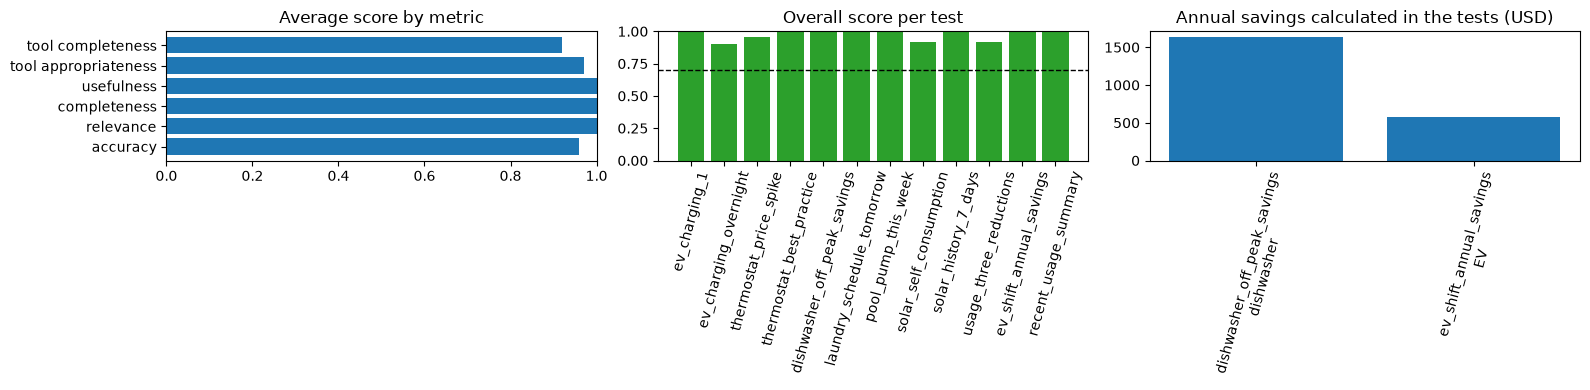

In [19]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
avg = report["metric_averages"]
axes[0].barh([m.replace("_", " ") for m in avg], list(avg.values()))
axes[0].set_xlim(0, 1); axes[0].set_title("Average score by metric")
per = pd.DataFrame(report["per_test"])
axes[1].bar(per["test_id"], per["overall"].fillna(0), color=["tab:green" if p else "tab:red" for p in per["passed"]])
axes[1].axhline(PASS_THRESHOLD, color="black", linestyle="--", linewidth=1)
axes[1].set_ylim(0, 1); axes[1].set_title("Overall score per test"); axes[1].tick_params(axis="x", rotation=75)

savings = []
for r in test_results:
    for m in (r["response"]["messages"] if isinstance(r.get("response"), dict) else []):
        if isinstance(m, ToolMessage) and m.name == "calculate_energy_savings":
            try:
                data = json.loads(m.content)
            except (TypeError, ValueError):
                continue
            if "annual_savings_usd" in data:
                savings.append((f"{r['test_id']}\n{data['device_type']}", data["annual_savings_usd"]))
if savings:
    axes[2].bar([s[0] for s in savings], [s[1] for s in savings])
    axes[2].set_title("Annual savings calculated in the tests (USD)"); axes[2].tick_params(axis="x", rotation=75)
else:
    axes[2].text(0.5, 0.5, "No savings calculations in this run", ha="center"); axes[2].set_axis_off()
plt.tight_layout(); plt.show()